# Member 1: Parts A, B and C
## Bank Marketing: predicting term-deposit subscription before the call

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)
%matplotlib inline

from src.config import FIG_DIR, RANDOM_STATE
from src.data_loading import load_raw
from src import eda, experiments as ex
from src.train import prepare_data
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("Ready")

Ready


## Part A: Machine learning problem analysis

In [2]:
raw = load_raw()
print("Shape:", raw.shape)
raw.head()

Shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
feature_desc = pd.DataFrame([
 ("age","client","numeric","Age in years"),
 ("job","client","nominal","Type of job (12 levels incl. 'unknown')"),
 ("marital","client","nominal","Marital status"),
 ("education","client","nominal","Highest education level"),
 ("default","client","nominal","Has credit in default?"),
 ("housing","client","nominal","Has a housing loan?"),
 ("loan","client","nominal","Has a personal loan?"),
 ("contact","last contact","nominal","Cellular or telephone"),
 ("month","last contact","nominal","Month of last contact"),
 ("day_of_week","last contact","nominal","Weekday of last contact"),
 ("duration","last contact","numeric","Call length in seconds (known only AFTER the call: leakage)"),
 ("campaign","campaign","numeric","Contacts in this campaign, incl. the last"),
 ("pdays","campaign","numeric","Days since previous campaign contact (999 = never)"),
 ("previous","campaign","numeric","Contacts before this campaign"),
 ("poutcome","campaign","nominal","Outcome of previous campaign"),
 ("emp_var_rate","macro","numeric","Employment variation rate (quarterly)"),
 ("cons_price_idx","macro","numeric","Consumer price index (monthly)"),
 ("cons_conf_idx","macro","numeric","Consumer confidence index (monthly)"),
 ("euribor3m","macro","numeric","3-month Euribor rate (daily)"),
 ("nr_employed","macro","numeric","Number employed (quarterly, thousands)"),
 ("y","target","binary","Subscribed a term deposit?"),
], columns=["feature","group","type","description"]).set_index("feature")
feature_desc

,group,type,description
feature,,,
age,client,numeric,Age in years
job,client,nominal,Type of job (12 levels incl. 'unknown')
marital,client,nominal,Marital status
education,client,nominal,Highest education level
default,client,nominal,Has credit in default?
housing,client,nominal,Has a housing loan?
loan,client,nominal,Has a personal loan?
contact,last contact,nominal,Cellular or telephone
month,last contact,nominal,Month of last contact


In [4]:
print(raw.dtypes.value_counts())
eda.class_balance(raw)

str        11
int64       5
float64     5
Name: count, dtype: int64


,count,pct
y,,
no,36548,88.73
yes,4640,11.27


This is a classification problem because the answer we want to predict is “yes” or “no” (will the client subscribe?), not a number. It is not regression, because regression predicts a number, like an amount of money. It is not clustering, because we already know the correct answer (y) for every client, so the model can learn from those answers. That makes it supervised learning.

## Part B: Supervised vs unsupervised learning
If clustering (unsupervised) were enough, the natural groups in the data would line up with who subscribes.
We fit k-means for k = 2 to 8 with the label hidden, then compare clusters with the real label
using the Adjusted Rand Index (ARI: 0 = no better than chance, 1 = perfect match).

In [5]:
raw_, clean, X_tr, X_te, y_tr, y_te = prepare_data()
probe = ex.unsupervised_probe(X_tr, y_tr)
probe

,silhouette,ARI_vs_label,max_cluster_sub_rate,min_cluster_sub_rate
k,,,,
2,0.1806,0.0618,0.1995,0.0567
3,0.1856,0.1042,0.6450,0.0559
4,0.1130,0.0432,0.6450,0.0400
5,0.1295,0.0544,0.6450,0.0397
6,0.1254,0.0352,0.6450,0.0389
7,0.1303,0.0363,0.6481,0.0392
8,0.1361,0.0239,0.6481,0.0425


We grouped the clients with k-means (k = 2 to 8) without showing it the answer. The ARI was very low for every k (at most 0.1042), so the groups did not match who subscribed. The silhouette score was also low (under 0.19), so the groups were weak. Some groups had a high subscription rate (about 65%), which could help with segmentation, but to rank clients we need the labels. So supervised learning is the right choice.

## Part C: Exploratory data analysis and data quality
### C1. Descriptive statistics and skewness

In [6]:
eda.descriptive_stats(raw)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
age,41188.0,40.024,10.421,17.000,32.000,38.000,47.000,98.000,0.785,0.791
duration,41188.0,258.285,259.279,0.000,102.000,180.000,319.000,4918.000,3.263,20.248
campaign,41188.0,2.568,2.770,1.000,1.000,2.000,3.000,56.000,4.763,36.980
pdays,41188.0,962.475,186.911,0.000,999.000,999.000,999.000,999.000,-4.922,22.229
previous,41188.0,0.173,0.495,0.000,0.000,0.000,0.000,7.000,3.832,20.109
emp_var_rate,41188.0,0.082,1.571,-3.400,-1.800,1.100,1.400,1.400,-0.724,-1.063
cons_price_idx,41188.0,93.576,0.579,92.201,93.075,93.749,93.994,94.767,-0.231,-0.830
cons_conf_idx,41188.0,-40.503,4.628,-50.800,-42.700,-41.800,-36.400,-26.900,0.303,-0.359
euribor3m,41188.0,3.621,1.734,0.634,1.344,4.857,4.961,5.045,-0.709,-1.407
nr_employed,41188.0,5167.036,72.252,4963.600,5099.100,5191.000,5228.100,5228.100,-1.044,-0.004


### C2. Missing values (real NaN and disguised 'unknown')

In [7]:
eda.quality_report(raw)

,dtype,n_unique,nan,unknown,unknown_pct
column,,,,,
age,int64,78,0,0,0.00
job,str,12,0,330,0.80
marital,str,4,0,80,0.19
education,str,8,0,1731,4.20
default,str,3,0,8597,20.87
housing,str,3,0,990,2.40
loan,str,3,0,990,2.40
contact,str,2,0,0,0.00
month,str,10,0,0,0.00


### C3. Duplicates

In [8]:
print(eda.duplicate_report(raw))
print("Feature-only duplicates (ignoring y):", raw.drop(columns="y").duplicated().sum())

{'exact_duplicate_rows': 12, 'rows_involved_in_duplicates': 24, 'feature_duplicates_with_conflicting_label': 0}
Feature-only duplicates (ignoring y): 12


### C4. Outliers (Tukey 1.5 x IQR fences)

In [9]:
eda.iqr_outliers(raw, ["age","duration","campaign","previous","cons_conf_idx"])

,lower_fence,upper_fence,n_outliers,pct
column,,,,
age,9.50,69.50,469,1.14
duration,-223.50,644.50,2963,7.19
campaign,-2.00,6.00,2406,5.84
previous,0.00,0.00,5625,13.66
cons_conf_idx,-52.15,-26.95,447,1.09


### C5. Inconsistencies, rare levels and noise

In [10]:
eda.inconsistency_checks(raw)

{'pdays999_but_previous>0': 4110,
 'poutcome_nonexistent_but_previous>0': 0,
 'previous>0_but_poutcome_nonexistent': 0,
 'housing_unknown_rows': 990,
 'housing_and_loan_unknown_same_rows': True,
 'default_yes_count': 3,
 'education_illiterate_count': 18,
 'duration_zero_calls': 4,
 'pdays_999_pct': np.float64(96.32)}

### C6. Class imbalance and distribution charts

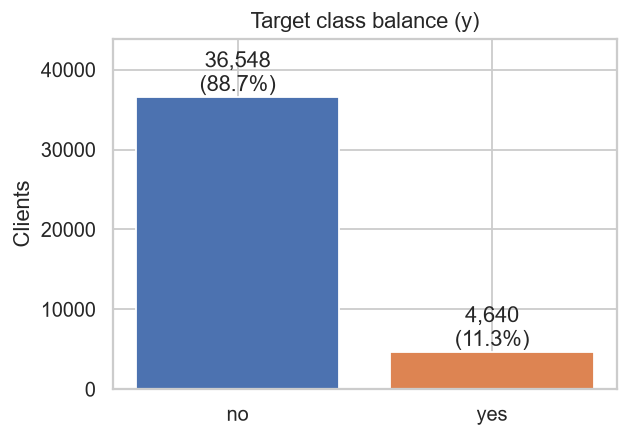

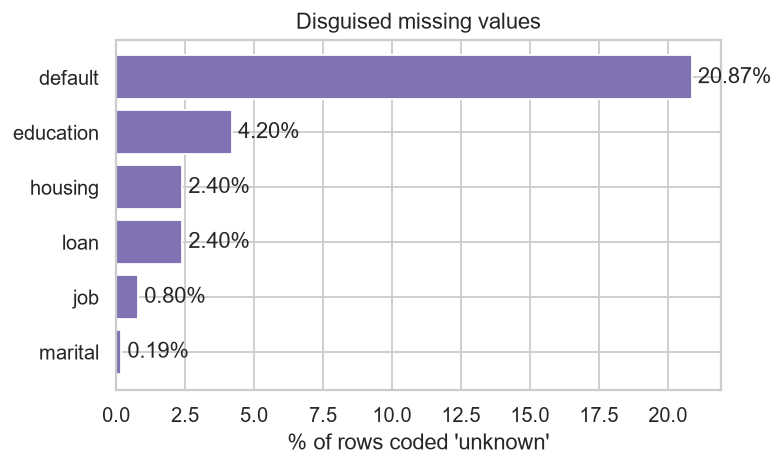

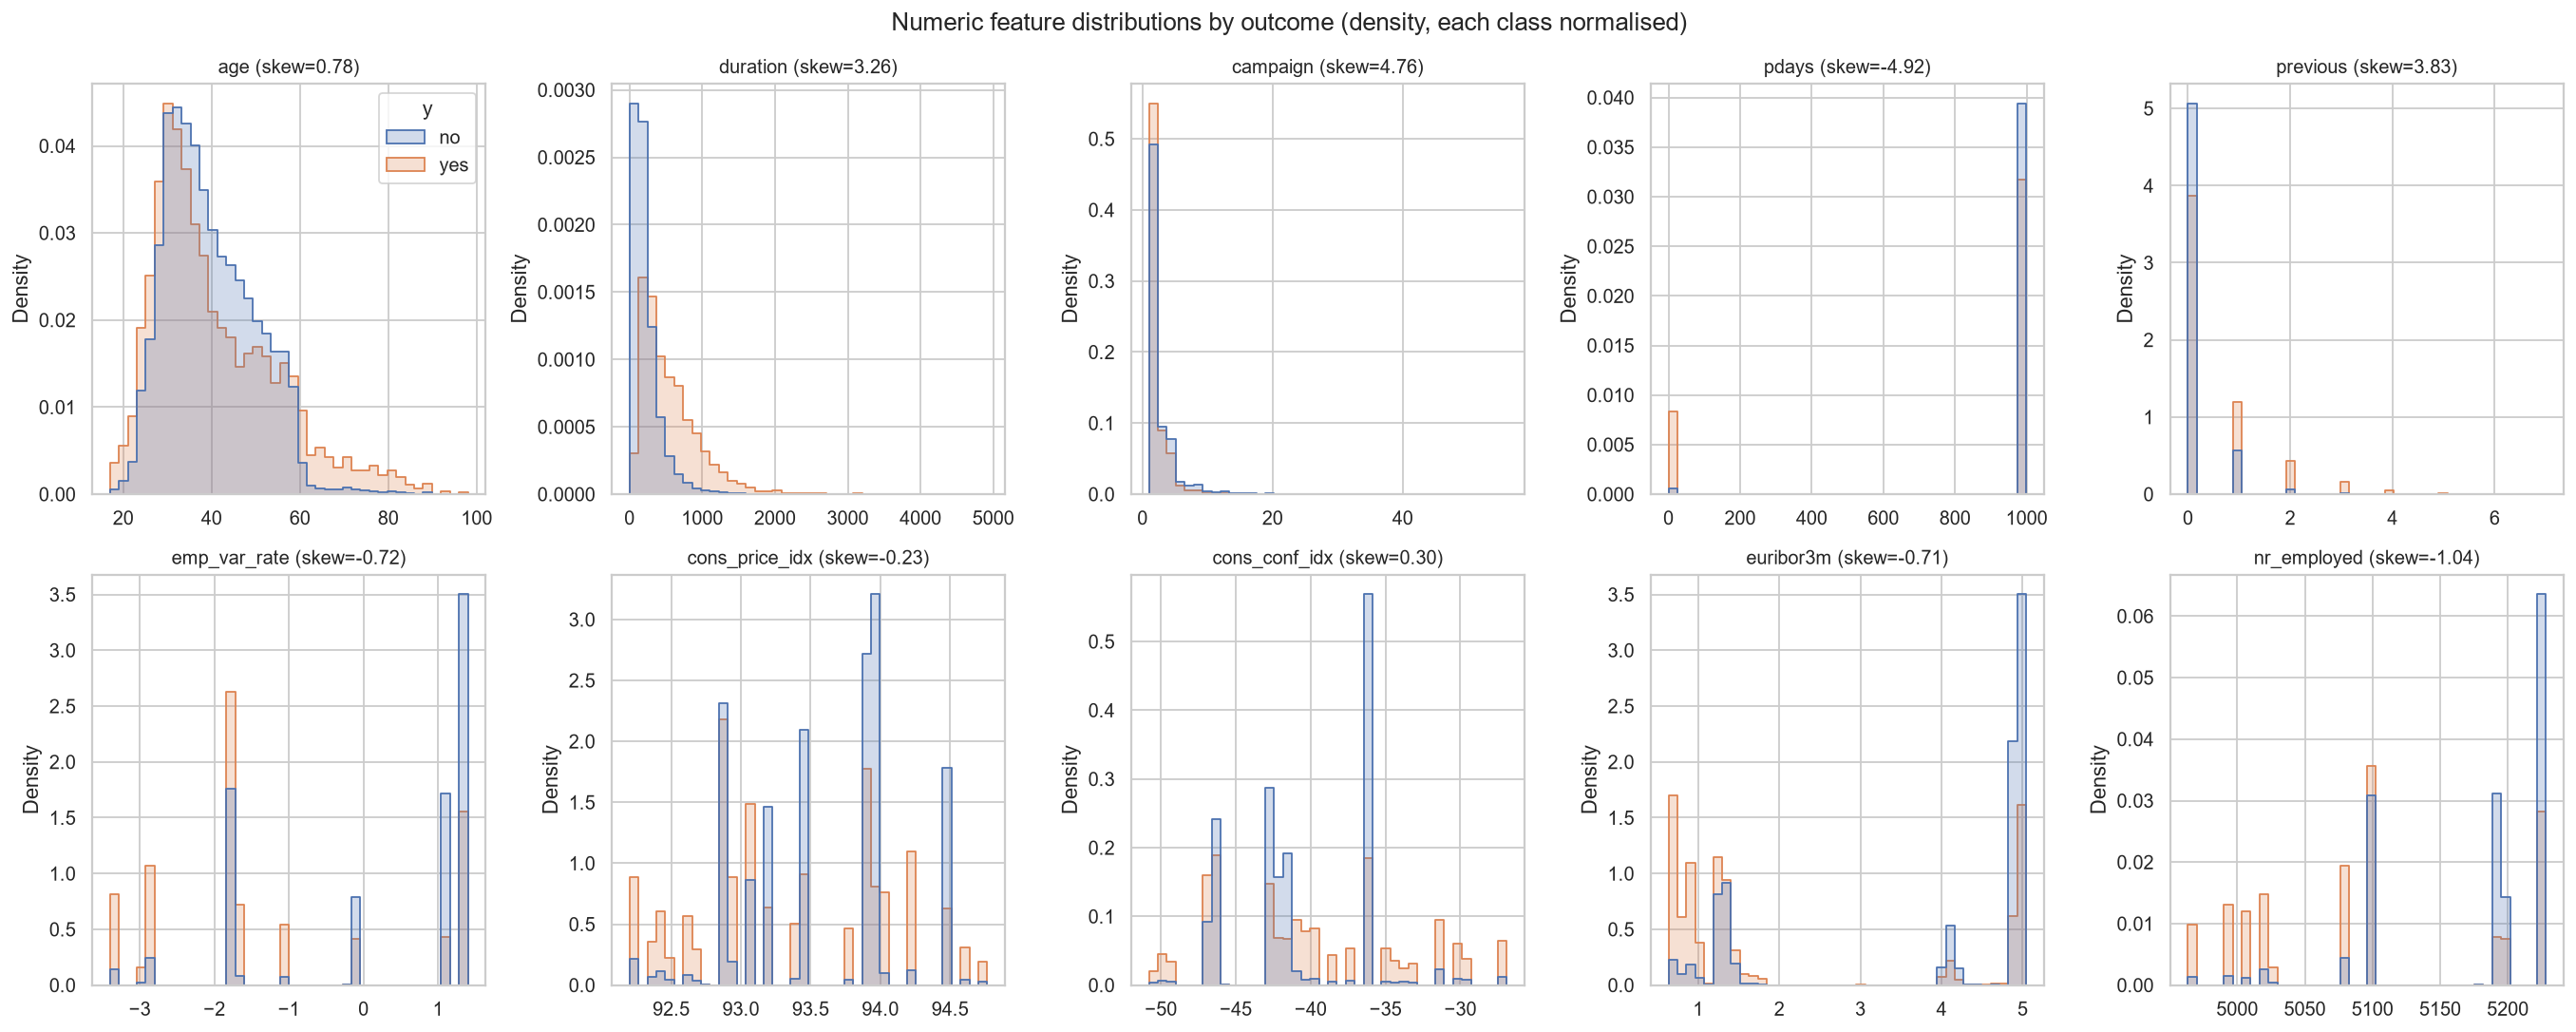

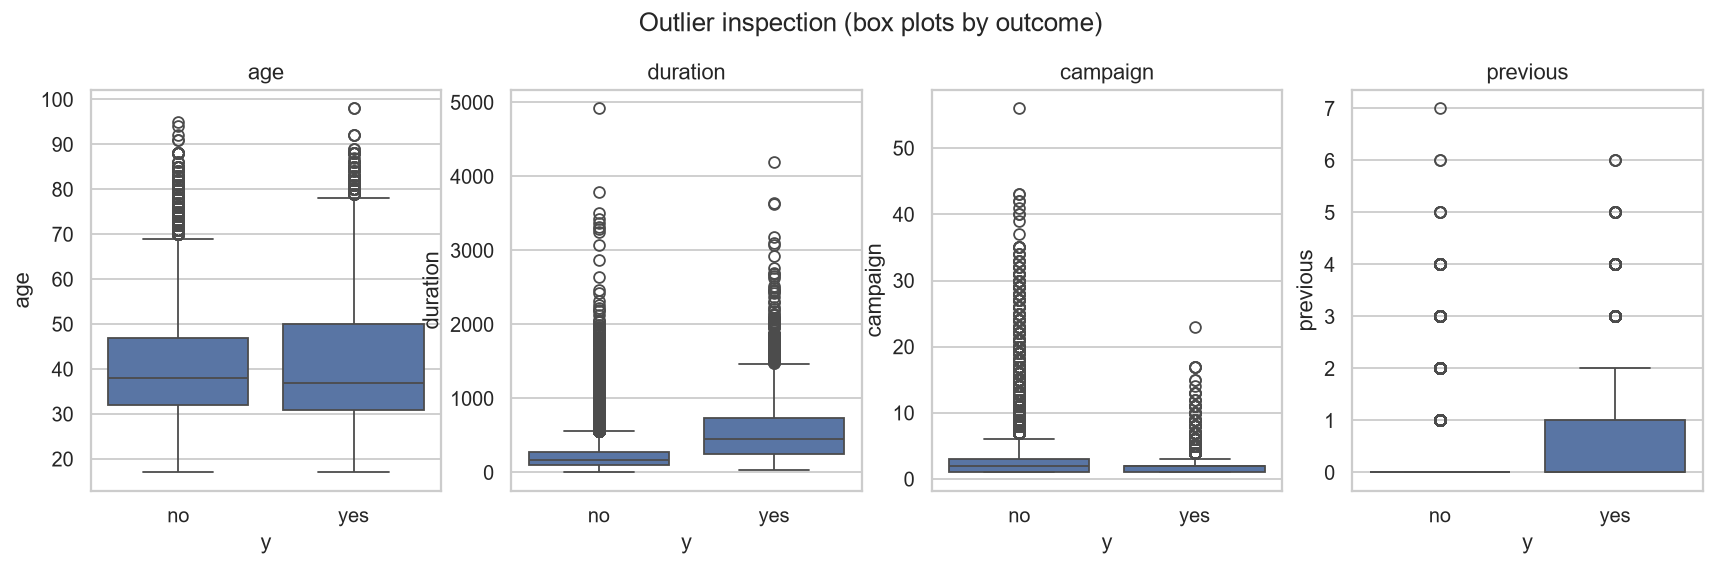

In [11]:
corr = eda.run_all_figures(raw)
for f in ["01_class_balance.png", "06_unknown_values.png", "02_numeric_distributions.png", "03_boxplots.png"]:
    display(Image(FIG_DIR / f))

### C7. Correlation and association with the target

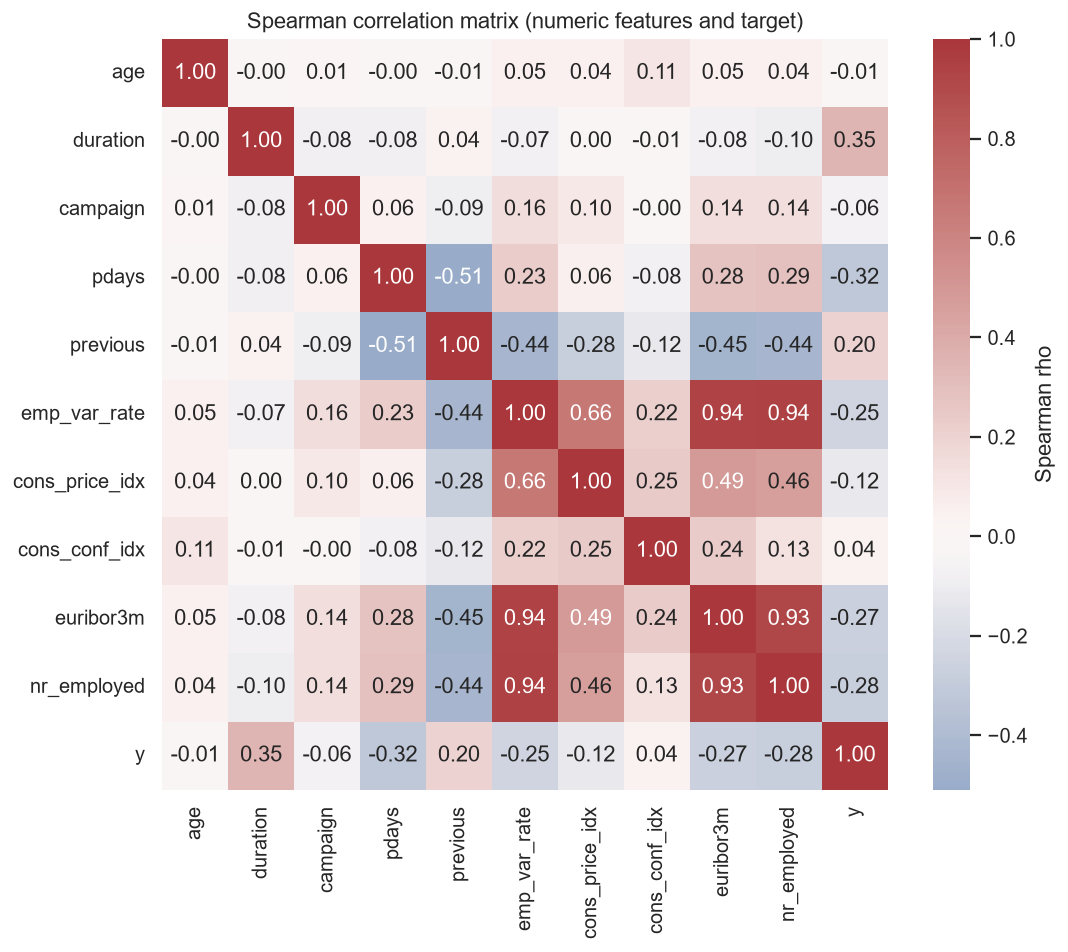

Spearman correlation with y (numeric):
duration          0.349
pdays            -0.325
nr_employed      -0.284
euribor3m        -0.267
emp_var_rate     -0.247
previous          0.201
cons_price_idx   -0.122
campaign         -0.064
cons_conf_idx     0.041
age              -0.012
Name: y, dtype: float64

Cramer's V with y (categorical):
poutcome       0.320
month          0.274
job            0.153
contact        0.145
default        0.099
education      0.068
marital        0.055
day_of_week    0.025
housing        0.012
loan           0.005
Name: cramers_v, dtype: float64


In [12]:
display(Image(FIG_DIR / "04_correlation_heatmap.png"))
print("Spearman correlation with y (numeric):")
print(corr["y"].drop("y").sort_values(key=abs, ascending=False).round(3))
print("\nCramer's V with y (categorical):")
print(eda.categorical_association(raw))

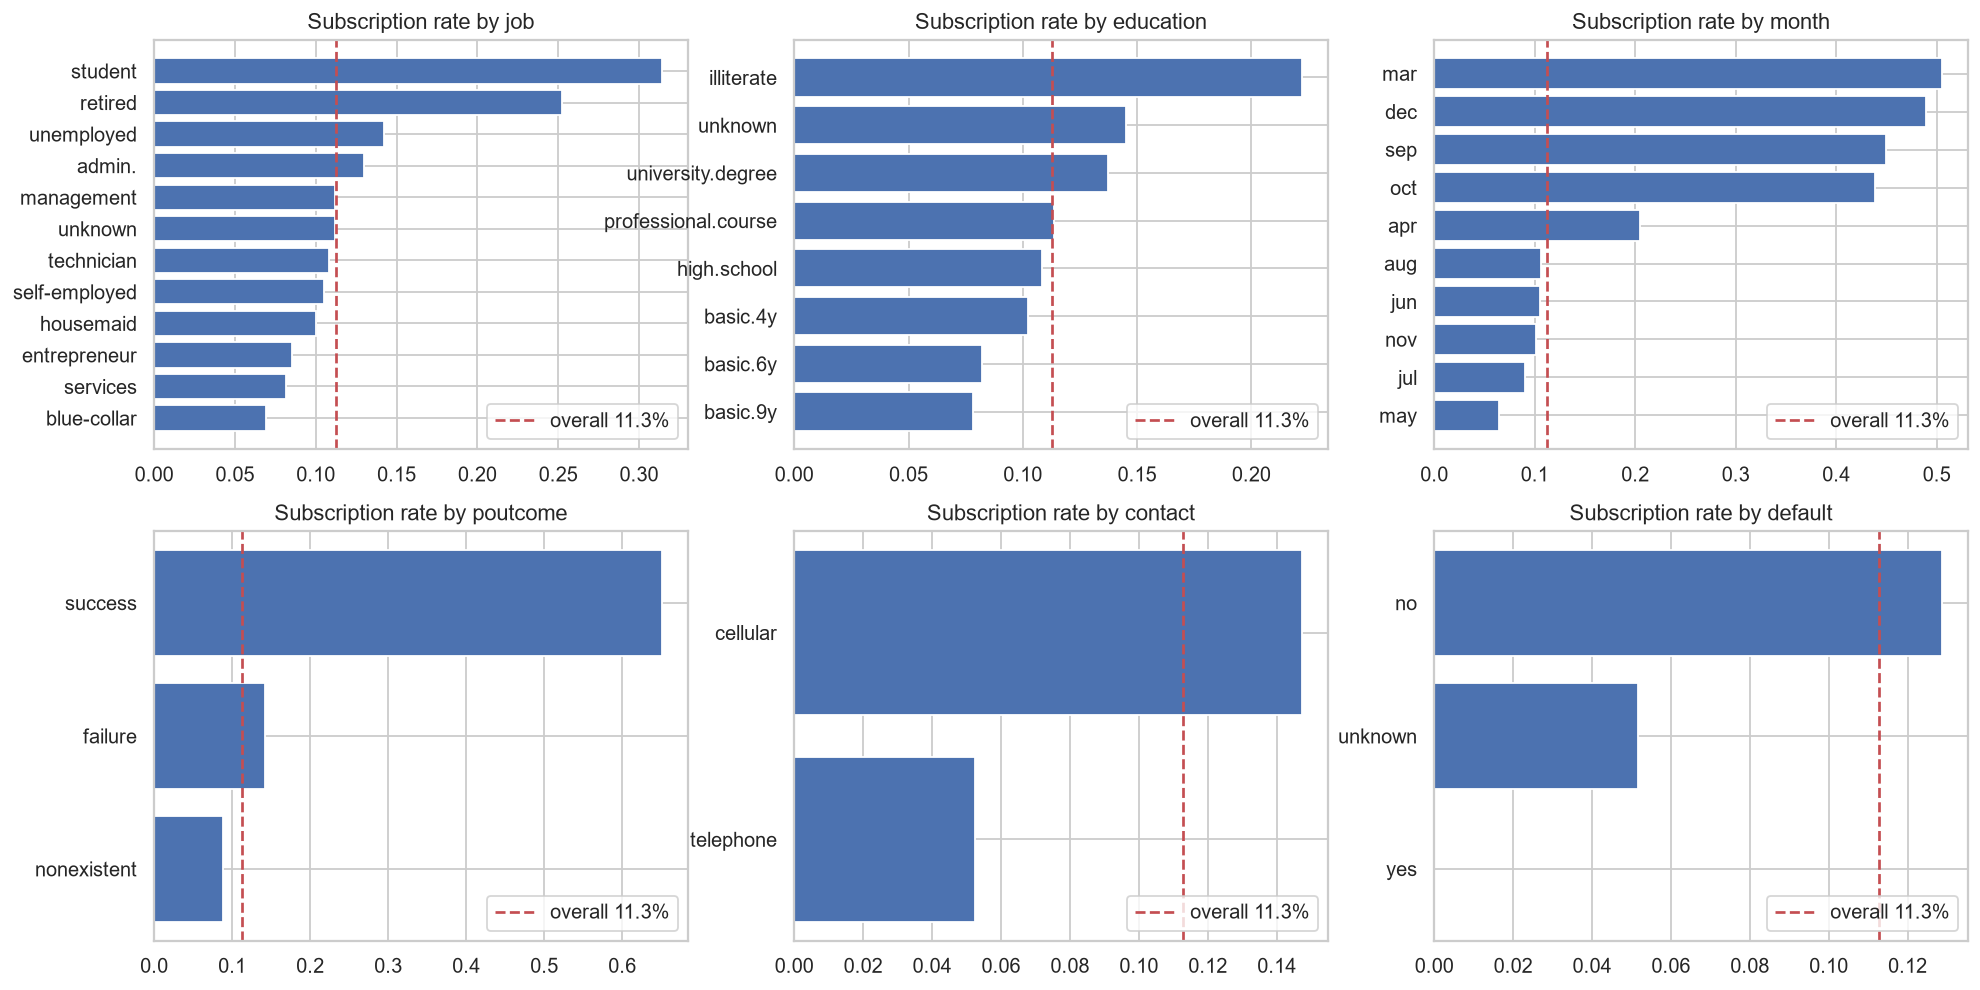

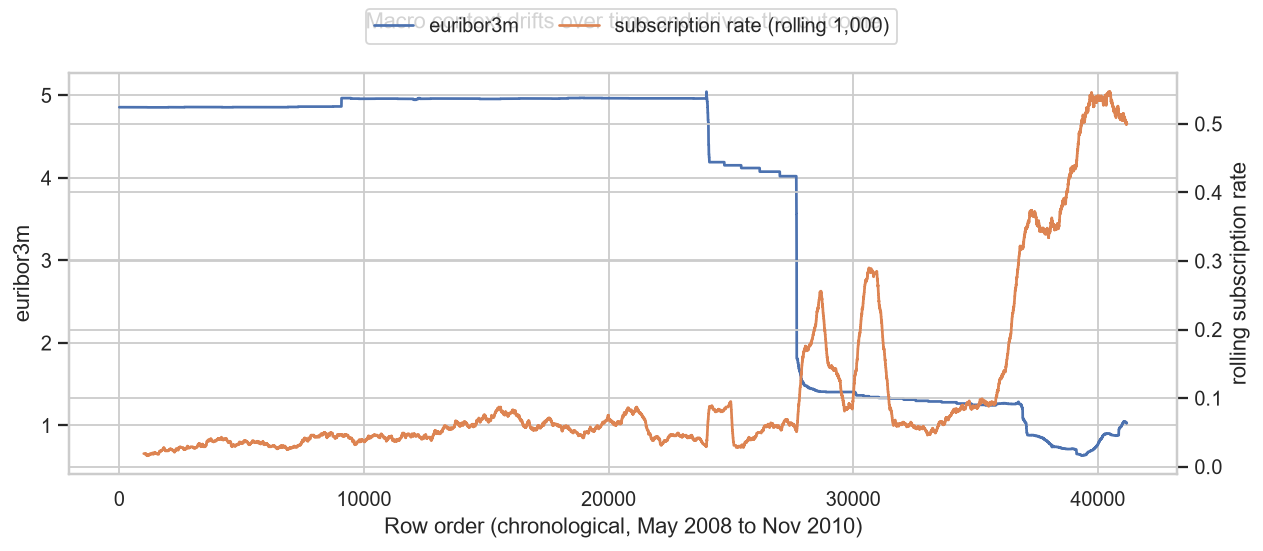

In [13]:
display(Image(FIG_DIR / "05_categorical_rates.png"))
display(Image(FIG_DIR / "07_temporal_drift.png"))